# Final Project
## Team member: Hung Jui Chao, Haojun Gong, Samuel Hsu, Shih-En Lee
* Q1: How do traffic patterns affect trip efficiency? Which service provide the best efficiency?
* Q2: Which routes generate the highest revenue efficiency?
* Q3: How do fares and driver earnings differ across services?

In [4]:
%pip install plotly

Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import statsmodels.api as sm

In [6]:
yellow = pd.read_parquet("yellow_tripdata_2026-05.parquet")
uberlyft = pd.read_parquet("fhvhv_tripdata_2026-05.parquet")

In [7]:
yellow.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,2,2026-05-01 00:04:59,2026-05-01 00:32:48,1.0,7.51,1.0,N,138,37,2,35.9,6.00,0.5,0.00,0.0,1.0,45.40,0.0,2.0,0.00
1,2,2026-05-01 00:37:05,2026-05-01 00:59:47,1.0,6.14,1.0,N,138,237,1,27.5,6.00,0.5,9.56,0.0,1.0,49.81,2.5,2.0,0.75
2,1,2026-05-01 00:34:05,2026-05-01 00:54:02,1.0,2.40,1.0,N,249,232,1,19.1,4.25,0.5,3.73,0.0,1.0,28.58,2.5,0.0,0.75
3,1,2026-05-01 00:55:07,2026-05-01 01:02:43,0.0,1.20,1.0,N,232,114,1,9.3,4.25,0.5,3.00,0.0,1.0,18.05,2.5,0.0,0.75
4,7,2026-05-01 00:44:13,2026-05-01 00:44:13,2.0,0.86,1.0,N,140,237,1,7.2,0.00,0.5,2.44,0.0,1.0,14.64,2.5,0.0,0.00


In [8]:
uberlyft.head()

,hvfhs_license_num,dispatching_base_num,originating_base_num,request_datetime,on_scene_datetime,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,trip_miles,...,congestion_surcharge,airport_fee,tips,driver_pay,shared_request_flag,shared_match_flag,access_a_ride_flag,wav_request_flag,wav_match_flag,cbd_congestion_fee
0,HV0003,B03404,B03404,2026-05-01 00:15:29,2026-05-01 00:18:00,2026-05-01 00:18:20,2026-05-01 00:35:57,164,263,3.370,...,2.75,0.0,0.0,23.52,N,N,N,N,N,1.5
1,HV0003,B03404,B03404,2026-05-01 00:53:01,2026-05-01 00:54:40,2026-05-01 00:57:24,2026-05-01 01:13:46,161,137,2.770,...,2.75,0.0,0.0,21.53,N,N,N,N,N,1.5
2,HV0005,B03406,None,2026-05-01 00:42:11,2026-05-01 00:44:12,2026-05-01 00:44:16,2026-05-01 01:00:33,48,265,4.868,...,0.00,0.0,4.1,19.30,N,N,N,N,N,1.5
3,HV0005,B03406,B03406,2026-05-01 00:34:36,2026-05-01 00:27:32,2026-05-01 00:27:39,2026-05-01 00:35:37,219,203,1.422,...,0.00,0.0,0.0,7.71,N,N,N,Y,Y,0.0
4,HV0005,B03406,None,2026-05-01 00:06:52,2026-05-01 00:09:38,2026-05-01 00:10:38,2026-05-01 00:17:20,41,42,1.535,...,0.00,0.0,0.0,6.53,N,N,N,N,N,0.0


### Import Zone Information

In [9]:
zone = pd.read_excel("Zone Info.xlsx")
zone.head()

FileNotFoundError: [Errno 2] No such file or directory: 'Zone Info.xlsx'

### Add into yellow cab and uber/lyft dataset

In [10]:
# Make sure Location IDs have the same data type
zone["LocationID"] = pd.to_numeric(zone["LocationID"], errors="coerce")
yellow["PULocationID"] = pd.to_numeric(yellow["PULocationID"], errors="coerce")
yellow["DOLocationID"] = pd.to_numeric(yellow["DOLocationID"], errors="coerce")

# Add Pickup Zone
yellow = yellow.merge(
    zone[["LocationID", "Zone"]].rename(
        columns={"Zone": "Pickup_Zone"}
    ),
    left_on="PULocationID",
    right_on="LocationID",
    how="left"
).drop(columns="LocationID")

# Add Dropoff Zone
yellow = yellow.merge(
    zone[["LocationID", "Zone"]].rename(
        columns={"Zone": "Dropoff_Zone"}
    ),
    left_on="DOLocationID",
    right_on="LocationID",
    how="left"
).drop(columns="LocationID")

NameError: name 'zone' is not defined

In [ ]:
yellow.head()

In [ ]:
# Add Pickup Zone
uberlyft = uberlyft.merge(
    zone[["LocationID", "Zone"]].rename(
        columns={"Zone": "Pickup_Zone"}
    ),
    left_on="PULocationID",
    right_on="LocationID",
    how="left"
).drop(columns="LocationID")

# Add Dropoff Zone
uberlyft = uberlyft.merge(
    zone[["LocationID", "Zone"]].rename(
        columns={"Zone": "Dropoff_Zone"}
    ),
    left_on="DOLocationID",
    right_on="LocationID",
    how="left"
).drop(columns="LocationID")

In [ ]:
uberlyft.head()

## Q1: How do traffic patterns affect trip efficiency?

### Step1: Data Preparation

In [ ]:
# Q1 - Step 1: Data Preparation

# Yellow Taxi
yellow["pickup_datetime"] = pd.to_datetime(
    yellow["tpep_pickup_datetime"]
)

yellow["dropoff_datetime"] = pd.to_datetime(
    yellow["tpep_dropoff_datetime"]
)

# Uber / Lyft
uberlyft["pickup_datetime"] = pd.to_datetime(
    uberlyft["pickup_datetime"]
)

uberlyft["dropoff_datetime"] = pd.to_datetime(
    uberlyft["dropoff_datetime"]
)

# Calculate trip duration and speed
for df in [yellow, uberlyft]:

    df["Trip_Duration"] = (
        df["dropoff_datetime"] - df["pickup_datetime"]
    ).dt.total_seconds() / 60

    df["Average_Speed"] = (
        df["trip_miles"] / (df["Trip_Duration"] / 60)
        if "trip_miles" in df.columns
        else df["trip_distance"] / (df["Trip_Duration"] / 60)
    )

    df["Hour"] = df["pickup_datetime"].dt.hour

    df["Weekday"] = df["pickup_datetime"].dt.day_name()

    df["Date"] = df["pickup_datetime"].dt.date

In [ ]:
print("Yellow Taxi:")
display(yellow[[
    "Trip_Duration", "Average_Speed",
    "Hour", "Weekday", "Date"
]].head())

print("Uber / Lyft:")
display(uberlyft[[
    "Trip_Duration", "Average_Speed",
    "Hour", "Weekday", "Date"
]].head())

### Check invalid Data: 
* Trip Duration <= 0
* Trip Distance <= 0
* Average Speed <= 0MPH or Average Speed > 80MPH
* Trip Duration is negative

In [ ]:
for name, df in [("Yellow Taxi", yellow), ("Uber/Lyft", uberlyft)]:

    print(f"\n{name}")

    print("Total Trips:", len(df))

    print("Invalid Duration:",
          (df["Trip_Duration"] <= 0).sum())

    print("Invalid Speed:",
          ((df["Average_Speed"] <= 0) |
           (df["Average_Speed"] > 80)).sum())

    print("Missing Speed:",
          df["Average_Speed"].isna().sum())

### Step4: Cleaning Data
#### Keep reasonable data:
* Trip Duration 1-180min
* Average Speed > 0 and <= 80MPH
* Trip Distance > 0
* PickUP Date in May

In [ ]:
# Q1 - Step 4: Data Cleaning

yellow_q1 = yellow[
    (yellow["Trip_Duration"].between(1, 180)) & 
    (yellow["Average_Speed"] > 0) &
    (yellow["Average_Speed"] <= 80) &
    (yellow["trip_distance"] > 0) &
    (yellow["pickup_datetime"].dt.year == 2026) &
    (yellow["pickup_datetime"].dt.month == 5)
].copy()

uberlyft_q1 = uberlyft[
    (uberlyft["Trip_Duration"].between(1, 180)) &
    (uberlyft["Average_Speed"] > 0) &
    (uberlyft["Average_Speed"] <= 80) &
    (uberlyft["trip_miles"] > 0) &
    (uberlyft["pickup_datetime"].dt.year == 2026) &
    (uberlyft["pickup_datetime"].dt.month == 5)
].copy()

print("Yellow Taxi:")
print("Original:", len(yellow))
print("Cleaned:", len(yellow_q1))

print("\nUber/Lyft:")
print("Original:", len(uberlyft))
print("Cleaned:", len(uberlyft_q1))

### Step5: Line Chart

In [ ]:
# Identify Uber and Lyft
uberlyft_q1["Service"] = uberlyft_q1["hvfhs_license_num"].map({
    "HV0003": "Uber",
    "HV0005": "Lyft"
})

yellow_q1["Service"] = "Yellow Taxi"

# Calculate average speed by hour
yellow_hourly = (
    yellow_q1.groupby(["Service", "Hour"])["Average_Speed"]
    .mean()
    .reset_index()
)

uberlyft_hourly = (
    uberlyft_q1.groupby(["Service", "Hour"])["Average_Speed"]
    .mean()
    .reset_index()
)

# Combine results
hourly_speed = pd.concat(
    [yellow_hourly, uberlyft_hourly],
    ignore_index=True
)

# Plot
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hourly_speed,
    x="Hour",
    y="Average_Speed",
    hue="Service",
    marker="o"
)

plt.title("Average Trip Speed by Hour — NYC (May 2026)")
plt.xlabel("Pickup Hour")
plt.ylabel("Average Speed (MPH)")
plt.xticks(range(24))
plt.legend(title="Service")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Step6: Traffic Heatmap
* Total traffic Heatmap
* Which Service provide the best service

In [ ]:
# Q1 - Step 6: Traffic Heatmap

# Combine Yellow Taxi and Uber/Lyft
traffic_data = pd.concat([
    yellow_q1[["Weekday", "Hour", "Average_Speed"]],
    uberlyft_q1[["Weekday", "Hour", "Average_Speed"]]
], ignore_index=True)

# Set weekday order
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Create pivot table
traffic_heatmap = traffic_data.pivot_table(
    index="Weekday",
    columns="Hour",
    values="Average_Speed",
    aggfunc="mean"
).reindex(weekday_order)

# Plot heatmap
plt.figure(figsize=(15, 6))

sns.heatmap(
    traffic_heatmap,
    cmap="RdYlGn",
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    cbar_kws={"label": "Average Speed (MPH)"}
)

plt.title("NYC Average Trip Speed by Weekday and Hour — May 2026")
plt.xlabel("Pickup Hour")
plt.ylabel("Day of Week")
plt.tight_layout()
plt.show()

### Best Service by Day & Hour

In [ ]:
# Q1 - Step 7: Best Service by Day and Hour

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Average speed for each service, weekday and hour
service_speed = (
    traffic_data
    .groupby(["Weekday", "Hour", "Service"])["Average_Speed"]
    .mean()
    .reset_index()
)

# Convert services into columns
speed_comparison = service_speed.pivot_table(
    index=["Weekday", "Hour"],
    columns="Service",
    values="Average_Speed"
)

services = ["Yellow Taxi", "Uber", "Lyft"]
speed_comparison = speed_comparison.reindex(columns=services)

# Find fastest service for each weekday and hour
best_service = speed_comparison.idxmax(axis=1)

# Convert service names into numeric values
service_codes = {
    "Yellow Taxi": 0,
    "Uber": 1,
    "Lyft": 2
}

best_service_codes = (
    best_service.map(service_codes)
    .unstack("Hour")
    .reindex(
        index=["Monday", "Tuesday", "Wednesday",
               "Thursday", "Friday", "Saturday", "Sunday"],
        columns=range(24)
    )
)

# Set colors
colors = ["#477db8", "#3a9b77", "#e0a04c"]
cmap = ListedColormap(colors)

# Plot
plt.figure(figsize=(16, 5))

sns.heatmap(
    best_service_codes,
    cmap=cmap,
    vmin=-0.5,
    vmax=2.5,
    linewidths=0.5,
    cbar=False
)

plt.title("Fastest Service by Weekday and Hour - NYC May 2026")
plt.xlabel("Pickup Hour")
plt.ylabel("Day of Week")

legend = [
    Patch(facecolor=colors[i], label=services[i])
    for i in range(3)
]

plt.legend(
    handles=legend,
    title="Fastest Service",
    bbox_to_anchor=(1.01, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


In [ ]:
# Count how many weekday-hour combinations each service wins

best_service_summary = (
    best_service.value_counts()
    .reindex(services, fill_value=0)
    .reset_index()
)

best_service_summary.columns = [
    "Service", "Hours Ranked Fastest"
]

best_service_summary["Percentage"] = (
    best_service_summary["Hours Ranked Fastest"]
    / len(best_service) * 100
).round(2)

display(best_service_summary)

## Find out Busiest time -> Check Driver Efficiency -> Check customer waiting time -> Decide which time should adjust their dirver schedule

### Step 8: Afternoon Coverage Analysis

In [ ]:
traffic_data = pd.concat([
    yellow_q1[["Service", "Weekday", "Hour", "Average_Speed"]],
    uberlyft_q1[["Service", "Weekday", "Hour", "Average_Speed"]]
], ignore_index=True)

traffic_data.head()

In [ ]:
# Step 8.1: Afternoon Trip Patterns

# Combine cleaned datasets
service_data = pd.concat([
    yellow_q1[[
        "Service", "Hour", "Weekday",
        "Trip_Duration", "Average_Speed"
    ]],
    uberlyft_q1[[
        "Service", "Hour", "Weekday",
        "Trip_Duration", "Average_Speed"
    ]]
], ignore_index=True)

# Filter afternoon hours (12 PM - 6 PM)
service_data = service_data[
    service_data["Hour"].between(0, 23)
].copy()

# Calculate hourly metrics
service_summary = (
    service_data
    .groupby(["Service", "Hour"])
    .agg(
        Total_Trips=("Trip_Duration", "size"),
        Avg_Trip_Duration=("Trip_Duration", "mean"),
        Avg_Speed=("Average_Speed", "mean")
    )
    .reset_index()
)

# Find peak hour for each service
peak_hours = service_summary.loc[
    service_summary.groupby("Service")["Total_Trips"].idxmax()
].copy()

print("Peak Hour by Service")
display(peak_hours.round(2))

# Find overall peak hour across all services
overall_hourly = (
    service_summary
    .groupby("Hour")["Total_Trips"]
    .sum()
    .reset_index()
)

overall_peak = overall_hourly.loc[
    overall_hourly["Total_Trips"].idxmax()
]

print(f"Overall Peak Hour: {int(overall_peak['Hour']):02d}:00")
print(f"Total Trips: {int(overall_peak['Total_Trips']):,}")

### Peak Hour Analysis

* The highest trip volume occurs at 18:00, with 1.53 million completed trips.

* Uber and Yellow Taxi reach their peak at 18:00, while Lyft peaks at 19:00.

* High trip volumes between 17:00 and 19:00 suggest increased service activity during the evening rush hour.

* Driver coverage should be evaluated during these hours to reduce pickup wait times and improve operational efficiency.

### Visualization

In [ ]:
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=service_summary,
    x="Hour",
    y="Total_Trips",
    hue="Service",
    marker="o",
    linewidth=2
)

# Mark peak hour for each service
for _, row in peak_hours.iterrows():
    plt.axvline(
        x=row["Hour"],
        linestyle="--",
        alpha=0.4
    )

    plt.annotate(
        f"{row['Service']} Peak: {int(row['Hour']):02d}:00",
        xy=(row["Hour"], row["Total_Trips"]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

plt.title("Hourly Completed Trips by Service")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Completed Trips")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Top 5 Busiest hour

In [ ]:
# Top 5 busiest hours across all services
top5_hours = (
    overall_hourly
    .sort_values("Total_Trips", ascending=False)
    .head(5)
    .copy()
)

top5_hours["Time"] = (
    top5_hours["Hour"].astype(str).str.zfill(2) + ":00"
)

display(top5_hours[["Time", "Total_Trips"]])

In [ ]:
# Step 8.4: Trip Volume vs. Trip Duration

plt.figure(figsize=(14, 7))

sns.scatterplot(
    data=service_summary,
    x="Hour",
    y="Avg_Trip_Duration",
    hue="Service",
    size="Total_Trips",
    sizes=(50, 900),
    alpha=0.65
)

plt.axvspan(17, 19, color="gray", alpha=0.12)

plt.title("Hourly Trip Volume vs. Average Trip Duration")
plt.xlabel("Hour of Day")
plt.ylabel("Average Trip Duration (Minutes)")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### Highest Volume time is not the longest Trip Duration time
### Trip Volume vs. Average Trip Duration

* 14:00–16:00: Trip durations reach their highest levels, potentially reducing driver turnover.

* 17:00–19:00: Trip volumes peak, indicating increased service activity during the evening rush hour.

* Operational Implication: Driver allocation should consider both trip volume and trip duration rather than trip volume alone.

* Recommendation: Evaluate additional driver coverage before the evening peak to maintain service efficiency.

### Step 9: Calculate Pickup Wait Time

In [ ]:
uberlyft_q1["request_datetime"] = pd.to_datetime(
    uberlyft_q1["request_datetime"]
)

uberlyft_q1["Pickup_Wait"] = (
    uberlyft_q1["pickup_datetime"] -
    uberlyft_q1["request_datetime"]
).dt.total_seconds() / 60

# Remove invalid waiting times
wait_data = uberlyft_q1[
    uberlyft_q1["Pickup_Wait"].between(0, 60)
].copy()

# Calculate average wait by service and hour
wait_summary = (
    wait_data
    .groupby(["Service", "Hour"])
    .agg(
        Avg_Wait=("Pickup_Wait", "mean"),
        Median_Wait=("Pickup_Wait", "median"),
        Total_Trips=("Pickup_Wait", "size")
    )
    .reset_index()
)

display(wait_summary.round(2))

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=wait_summary,
    x="Hour",
    y="Avg_Wait",
    hue="Service",
    marker="o"
)

plt.title("Average Pickup Wait Time by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Pickup Wait (Minutes)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Pickup Wait Time Analysis

* 04:00: Uber records the longest pickup wait (~7.3 min), suggesting a potential early-morning coverage gap.

* 14:00–16:00: Despite longer trip durations, pickup waits remain relatively stable at 5.3–5.5 minutes.

* 18:00: The highest trip volume does not result in longer pickup waits (~5.1 min).

* Operational Implication: High trip volume alone does not indicate insufficient driver coverage. Driver allocation should consider actual pickup wait times.

### Step 10: Driver Productivity Proxy

In [ ]:
productivity_summary = (
    service_data
    .groupby(["Service", "Hour"])
    .agg(
        Completed_Trips=("Trip_Duration", "size"),
        Total_Trip_Minutes=("Trip_Duration", "sum")
    )
    .reset_index()
)

# Trips per Occupied Hour = Completed Trips / Total Trip Duration(Hours)
# Shows the efficiency of driver

productivity_summary["Trips_per_Occupied_Hour"] = (
    productivity_summary["Completed_Trips"] /
    (productivity_summary["Total_Trip_Minutes"] / 60)
)

productivity_summary.round(2).head()

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=productivity_summary,
    x="Hour",
    y="Trips_per_Occupied_Hour",
    hue="Service",
    marker="o"
)

plt.title("Completed Trips per Occupied Vehicle Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Trips per Occupied Hour")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Occupied-Time Throughput Analysis

* 14:00–16:00: All three services experience their lowest occupied-time throughput due to longer average trip durations.

* Uber: Records the lowest throughput at approximately 2.43 trips per occupied hour at 15:00.

* After 17:00: Throughput improves as average trip durations decrease.

* Operational Implication: Afternoon driver coverage should account for longer trip durations, while evening coverage should consider higher trip volumes.

### Time Period	Recommendation
* 14:00–16:00	Longest trip duration and lowest occupied-time throughput	Maintain sufficient coverage to account for longer trips
* 17:00–19:00	Highest completed trip volume, but relatively stable pickup waits	Maintain peak-hour coverage and monitor waiting times
* 22:00–04:00	Pickup wait increases, especially for Uber	Investigate potential overnight driver coverage gaps

### Step 11: Operation Decision Heatmap
### Metric
* Pickup Wait, Weight: 50%, Reason: Direct customer service KPI
* Trip Volume, Weight: 30%, Reason: Service activity
* Trip Duration, Weight: 20%, Reason: Vehicle time commitment

In [ ]:
# Combine trip metrics with pickup wait
decision_data = service_summary.merge(
    wait_summary[["Service", "Hour", "Avg_Wait"]],
    on=["Service", "Hour"],
    how="inner"
)

# Keep Uber and Lyft
decision_data = decision_data[
    decision_data["Service"].isin(["Uber", "Lyft"])
].copy()

# Normalize within each service
metrics = ["Total_Trips", "Avg_Trip_Duration", "Avg_Wait"]

for metric in metrics:
    min_val = decision_data.groupby("Service")[metric].transform("min")
    max_val = decision_data.groupby("Service")[metric].transform("max")

    decision_data[metric + "_Norm"] = (
        (decision_data[metric] - min_val) /
        (max_val - min_val).replace(0, np.nan)
    ).fillna(0)

# Calculate priority score
decision_data["Priority_Score"] = (
    0.50 * decision_data["Avg_Wait_Norm"] +
    0.30 * decision_data["Total_Trips_Norm"] +
    0.20 * decision_data["Avg_Trip_Duration_Norm"]
) * 100

display(decision_data.round(2))

In [ ]:
# Create Operation Decision heat map
heatmap_data = decision_data.pivot(
    index="Service",
    columns="Hour",
    values="Priority_Score"
)

plt.figure(figsize=(16, 4))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="RdYlGn_r",
    vmin=heatmap_data.min().min(),
    vmax=heatmap_data.max().max(),
    linewidths=0.5,
    cbar_kws={"label": "Relative Operational Priority"}
)

plt.title("Hourly Driver Coverage Priority Heatmap")
plt.xlabel("Hour of Day")
plt.ylabel("Service")
plt.tight_layout()
plt.show()

In [ ]:
top_priority = (
    decision_data
    .sort_values("Priority_Score", ascending=False)
    .head(5)
)

display(
    top_priority[[
        "Service",
        "Hour",
        "Total_Trips",
        "Avg_Trip_Duration",
        "Avg_Wait",
        "Priority_Score"
    ]].round(2)
)

### Operational Recommendations

#### Prioritize Afternoon Driver Coverage (14:00–17:00)

* Longer trip durations and higher operational priority scores suggest that afternoon hours should receive additional attention in driver coverage planning.

#### Maintain Evening Peak Coverage (17:00–19:00)

* Although completed trip volume peaks at 18:00, pickup wait times remain relatively stable, suggesting that current coverage may be handling observed trip activity effectively.

#### Review Late-Night Driver Availability (22:00–23:00)

* Increasing pickup wait times during late-night hours indicate an opportunity to investigate driver availability and improve service responsiveness.

### Step 12: Use ML to forecast future service volume in different time

In [ ]:
# Prepare Data for Machine Learning
# Combine cleaned datasets
ml_data = pd.concat([
    yellow_q1[["Date", "Hour", "Weekday", "Service"]],
    uberlyft_q1[["Date", "Hour", "Weekday", "Service"]]
], ignore_index=True)

# Convert Date to datetime
ml_data["Date"] = pd.to_datetime(ml_data["Date"])

# Count completed trips by date, hour and service
ml_hourly = (
    ml_data
    .groupby(["Date", "Hour", "Weekday", "Service"])
    .size()
    .reset_index(name="Total_Trips")
)

# Sort data
ml_hourly = ml_hourly.sort_values(
    ["Date", "Hour", "Service"]
).reset_index(drop=True)

print("Dataset Shape:", ml_hourly.shape)

display(ml_hourly.tail(10))

In [ ]:
# Check data completeness

print("Number of Dates:", ml_hourly["Date"].nunique())
print("Number of Services:", ml_hourly["Service"].nunique())

print("\nMissing Values:")
print(ml_hourly.isnull().sum())

print("\nTrip Volume Summary:")
display(
    ml_hourly.groupby("Service")["Total_Trips"].describe().round(2)
)

In [ ]:
# Train-Test Split

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Convert categorical features into dummy variables
ml_model = pd.get_dummies(
    ml_hourly,
    columns=["Weekday", "Service"],
    drop_first=False
)

# Define features
features = [
    col for col in ml_model.columns
    if col not in ["Date", "Total_Trips"]
]

X = ml_model[features]
y = ml_model["Total_Trips"]

# Time-based split
train_mask = ml_model["Date"] < "2026-05-25"
test_mask = ml_model["Date"] >= "2026-05-25"

X_train = X[train_mask]
X_test = X[test_mask]

y_train = y[train_mask]
y_test = y[test_mask]

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nFeatures:")
print(features)

In [ ]:
# Train Random Forest Regression

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Predict testing data
y_pred = rf_model.predict(X_test)

print("Random Forest Model Training Completed!")

In [ ]:
# Model Evaluation

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Random Forest Model Performance")
print(f"MAE: {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²: {r2:.4f}")

In [ ]:
# Actual vs. Predicted

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 7))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.5
)

max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [0, max_val],
    [0, max_val],
    "r--",
    label="Perfect Prediction"
)

plt.title("Random Forest: Actual vs. Predicted Trips")
plt.xlabel("Actual Completed Trips")
plt.ylabel("Predicted Completed Trips")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Cross-Validation

from sklearn.model_selection import TimeSeriesSplit, cross_validate

# Sort training data chronologically
train_data = ml_model.loc[train_mask].sort_values(
    "Date"
).copy()

X_cv = train_data[features]
y_cv = train_data["Total_Trips"]

# Each day contains 72 observations (24 hours × 3 services)
tscv = TimeSeriesSplit(
    n_splits=4,
    test_size=72 * 4
)

cv_results = cross_validate(
    rf_model,
    X_cv,
    y_cv,
    cv=tscv,
    scoring="r2",
    return_train_score=True,
    n_jobs=-1
)

print(
    f"Mean training R²: "
    f"{cv_results['train_score'].mean():.4f}"
)

print(
    f"Mean validation R²: "
    f"{cv_results['test_score'].mean():.4f}"
)

print(
    f"Validation R² standard deviation: "
    f"{cv_results['test_score'].std():.4f}"
)

In [ ]:
# Prediction Error Heatmap

# Create prediction results
results = ml_hourly.loc[test_mask, [
    "Date", "Hour", "Service"
]].copy()

results["Actual"] = y_test.to_numpy()
results["Predicted"] = y_pred

# Calculate Absolute Percentage Error
results["APE"] = (
    abs(results["Actual"] - results["Predicted"]) /
    results["Actual"].replace(0, np.nan)
) * 100

# Average error by service and hour
error_heatmap = results.pivot_table(
    index="Service",
    columns="Hour",
    values="APE",
    aggfunc="mean"
)

plt.figure(figsize=(16, 4))

sns.heatmap(
    error_heatmap,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn_r",
    linewidths=0.5,
    cbar_kws={"label": "Mean Absolute Percentage Error (%)"}
)

plt.title("Random Forest Prediction Error Heatmap")
plt.xlabel("Hour of Day")
plt.ylabel("Service")
plt.tight_layout()
plt.show()

### Forecast June service Volume using ML

In [ ]:
# Retrain Random Forest with Full May Data

from sklearn.ensemble import RandomForestRegressor

rf_final = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# Train with all May observations
rf_final.fit(X, y)

print("Final Random Forest Model Trained!")
print("Training Observations:", len(X))

In [ ]:
# Create June 2026 Dataset

import pandas as pd
import numpy as np

# June dates
june_dates = pd.date_range(
    start="2026-06-01",
    end="2026-06-30",
    freq="D"
)

# Create all combinations
june_data = pd.MultiIndex.from_product(
    [
        june_dates,
        range(24),
        ["Uber", "Lyft", "Yellow Taxi"]
    ],
    names=["Date", "Hour", "Service"]
).to_frame(index=False)

# Add weekday
june_data["Weekday"] = june_data["Date"].dt.day_name()

print("June Dataset Shape:", june_data.shape)

display(june_data.head(10))

In [ ]:
# Predict June Trip Volume

# Encode categorical variables
june_encoded = pd.get_dummies(
    june_data,
    columns=["Weekday", "Service"],
    drop_first=False
)

# Match training features
X_june = june_encoded.reindex(
    columns=features,
    fill_value=0
)

# Predict
june_data["Predicted_Trips"] = rf_final.predict(X_june)

# Round predictions to whole trips
june_data["Predicted_Trips"] = (
    june_data["Predicted_Trips"]
    .round()
    .clip(lower=0)
    .astype(int)
)

display(june_data.head(10))

In [ ]:
# June Peak Hour Analysis

june_hourly = (
    june_data
    .groupby(["Service", "Hour"])["Predicted_Trips"]
    .mean() # Using mean() since we like to know the average
    .reset_index()
)

# Find peak hour for each service
june_peak = june_hourly.loc[
    june_hourly.groupby("Service")["Predicted_Trips"].idxmax()
]

print("Predicted June Peak Hours by Service")

display(june_peak.round(0))

In [ ]:
# June Predicted Hourly Trip Volume

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=june_hourly,
    x="Hour",
    y="Predicted_Trips",
    hue="Service",
    marker="o",
    linewidth=2.5,
    palette={
        "Lyft": "tab:blue",
        "Uber": "tab:orange",
        "Yellow Taxi": "tab:green"
    }
)

plt.axvspan(14, 17, color="gray", alpha=0.12,
            label="Afternoon Coverage")

plt.title("June 2026 Predicted Hourly Trip Volume")
plt.xlabel("Hour of Day")
plt.ylabel("Average Predicted Trips per Hour")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### June Forecast the busiest time is still from 14-17

In [ ]:
# May Actual vs. June Predicted Heatmaps

# May actual average hourly trips
may_hourly = (
    ml_hourly
    .groupby(["Service", "Hour"])["Total_Trips"]
    .mean()
    .reset_index()
)

may_heatmap = may_hourly.pivot(
    index="Service",
    columns="Hour",
    values="Total_Trips"
)

june_heatmap = june_hourly.pivot(
    index="Service",
    columns="Hour",
    values="Predicted_Trips"
)

# Same color scale for fair comparison
vmin = min(may_heatmap.min().min(),
           june_heatmap.min().min())

vmax = max(may_heatmap.max().max(),
           june_heatmap.max().max())

fig, axes = plt.subplots(2, 1, figsize=(16, 7))

sns.heatmap(
    may_heatmap,
    ax=axes[0],
    cmap="YlOrRd",
    vmin=vmin,
    vmax=vmax,
    annot=True,
    fmt=".0f",
    linewidths=0.5,
    cbar_kws={"label": "Average Trips per Hour"}
)

axes[0].set_title("May 2026 Actual Hourly Trip Volume")
axes[0].set_xlabel("")
axes[0].set_ylabel("Service")

sns.heatmap(
    june_heatmap,
    ax=axes[1],
    cmap="YlOrRd",
    vmin=vmin,
    vmax=vmax,
    annot=True,
    fmt=".0f",
    linewidths=0.5,
    cbar_kws={"label": "Average Trips per Hour"}
)

axes[1].set_title("June 2026 Predicted Hourly Trip Volume")
axes[1].set_xlabel("Hour of Day")
axes[1].set_ylabel("Service")

plt.tight_layout()
plt.show()

In [ ]:
# Predicted Peak Hour by Service

# Sort services
june_peak_plot = june_peak.set_index("Service").loc[
    ["Lyft", "Uber", "Yellow Taxi"]
].reset_index()

colors = ["tab:blue", "tab:orange", "tab:green"]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    june_peak_plot["Service"],
    june_peak_plot["Predicted_Trips"],
    color=colors,
    width=0.65
)

# Add labels for all three services
for bar, (_, row) in zip(bars, june_peak_plot.iterrows()):

    height = bar.get_height()

    ax.annotate(
        f"{height:,.0f}\n{int(row['Hour']):02d}:00",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_title("June 2026 Predicted Peak Hours by Service")
ax.set_xlabel("Service")
ax.set_ylabel("Average Predicted Trips per Hour")

ax.set_ylim(0, june_peak_plot["Predicted_Trips"].max() * 1.2)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### June 2026 Trip Volume Forecast

* Uber: Predicted peak activity occurs at 18:00, averaging approximately 27,984 completed trips.

* Lyft: Peak activity is expected at 19:00, averaging approximately 12,473 trips.

* Yellow Taxi: Predicted peak activity occurs at 18:00, averaging approximately 8,026 trips.

* Operational Implication: Maintain sufficient evening driver coverage while monitoring afternoon trip durations and pickup wait times.

* Recommendation: Use predicted hourly trip volumes to support driver coverage planning, particularly during the afternoon-to-evening transition.

## Q3: How can Yellow Taxi drivers capture unmet Uber/Lyft demand gaps to increase taxi ridership and revenue?

In [11]:
# Step 1: 檢查變數與欄位
for var_name in ["yellow_q1", "uberlyft_q1"]:
    if var_name in globals():
        df_tmp = globals()[var_name]
        print(f"✔ {var_name} 已存在 | 筆數: {len(df_tmp):,}")
        print("  欄位:", list(df_tmp.columns))
    else:
        print(f"✘ {var_name} 尚未存在（需要先執行前面建立它的程式）")

✘ yellow_q1 尚未存在（需要先執行前面建立它的程式）
✘ uberlyft_q1 尚未存在（需要先執行前面建立它的程式）


In [1]:
import numpy as np
import pandas as pd

YELLOW_PATH = "yellow_tripdata_2026-05.parquet"
FHVHV_PATH = "fhvhv_tripdata_2026-05.parquet"

# 1. 讀取資料
yellow = pd.read_parquet(YELLOW_PATH)
uberlyft = pd.read_parquet(FHVHV_PATH)

# 2. 時間欄位轉換
yellow["pickup_datetime"] = pd.to_datetime(yellow["tpep_pickup_datetime"])
yellow["dropoff_datetime"] = pd.to_datetime(yellow["tpep_dropoff_datetime"])
uberlyft["pickup_datetime"] = pd.to_datetime(uberlyft["pickup_datetime"])
uberlyft["dropoff_datetime"] = pd.to_datetime(uberlyft["dropoff_datetime"])

# 3. 計算 Trip_Duration、Average_Speed 與時間欄位
yellow["Trip_Duration"] = (
    yellow["dropoff_datetime"] - yellow["pickup_datetime"]
).dt.total_seconds() / 60

yellow["Average_Speed"] = np.where(
    (yellow["Trip_Duration"] > 0) & (yellow["trip_distance"] > 0),
    yellow["trip_distance"] / (yellow["Trip_Duration"] / 60),
    np.nan
)
yellow["Hour"] = yellow["pickup_datetime"].dt.hour
yellow["Weekday"] = yellow["pickup_datetime"].dt.day_name()
yellow["Date"] = yellow["pickup_datetime"].dt.date

uberlyft["Trip_Duration"] = (
    uberlyft["dropoff_datetime"] - uberlyft["pickup_datetime"]
).dt.total_seconds() / 60

uberlyft["Average_Speed"] = np.where(
    (uberlyft["Trip_Duration"] > 0) & (uberlyft["trip_miles"] > 0),
    uberlyft["trip_miles"] / (uberlyft["Trip_Duration"] / 60),
    np.nan
)
uberlyft["Hour"] = uberlyft["pickup_datetime"].dt.hour
uberlyft["Weekday"] = uberlyft["pickup_datetime"].dt.day_name()
uberlyft["Date"] = uberlyft["pickup_datetime"].dt.date

# 4. 清理異常值並保留 2026 年 5 月合理行程
yellow_q1 = yellow[
    (yellow["Trip_Duration"].between(1, 180)) &
    (yellow["Average_Speed"] > 0) &
    (yellow["Average_Speed"] <= 80) &
    (yellow["trip_distance"] > 0) &
    (yellow["pickup_datetime"].dt.year == 2026) &
    (yellow["pickup_datetime"].dt.month == 5)
].copy()

uberlyft_q1 = uberlyft[
    (uberlyft["Trip_Duration"].between(1, 180)) &
    (uberlyft["Average_Speed"] > 0) &
    (uberlyft["Average_Speed"] <= 80) &
    (uberlyft["trip_miles"] > 0) &
    (uberlyft["pickup_datetime"].dt.year == 2026) &
    (uberlyft["pickup_datetime"].dt.month == 5)
].copy()

# 5. 加上 Service 標籤
yellow_q1["Service"] = "Yellow Taxi"
uberlyft_q1["Service"] = uberlyft_q1["hvfhs_license_num"].map({
    "HV0003": "Uber",
    "HV0005": "Lyft"
})

print(f"✔ yellow_q1 完成: {len(yellow_q1):,} 筆")
print(f"✔ uberlyft_q1 完成: {len(uberlyft_q1):,} 筆")

✔ yellow_q1 完成: 3,912,000 筆
✔ uberlyft_q1 完成: 22,119,701 筆


## PART 1 

In [2]:
import numpy as np
import pandas as pd

def classify_period(weekday, hour):
    is_weekend = weekday in ["Saturday", "Sunday"]
    if not is_weekend:
        return "Peak" if ((7 <= hour <= 9) or (16 <= hour <= 19)) else "Off-Peak"
    else:
        return "Peak" if (12 <= hour <= 22) else "Off-Peak"

# 篩選 Uber/Lyft 並去除缺漏的 PULocationID
fhv_clean = uberlyft_q1.dropna(subset=["PULocationID"]).copy()
fhv_clean["PULocationID"] = fhv_clean["PULocationID"].astype(int)

# 取熱門 Top 30 出發區（兼顧代表性與訓練速度）
top30_pu = fhv_clean["PULocationID"].value_counts().head(30).index

fhv_hourly = (
    fhv_clean[fhv_clean["PULocationID"].isin(top30_pu)]
    .groupby(["Date", "Hour", "PULocationID"])
    .size()
    .rename("FHV_Demand")
    .reset_index()
)

# 補齊完整 Date x Hour x PULocationID 網格
all_dates = sorted(fhv_hourly["Date"].unique())
all_hours = list(range(24))

grid = pd.MultiIndex.from_product(
    [all_dates, all_hours, top30_pu],
    names=["Date", "Hour", "PULocationID"]
).to_frame(index=False)

panel = grid.merge(fhv_hourly, on=["Date", "Hour", "PULocationID"], how="left")
panel["FHV_Demand"] = panel["FHV_Demand"].fillna(0)

# 建立時間與尖峰/離峰特徵
panel["Datetime"] = pd.to_datetime(panel["Date"].astype(str)) + pd.to_timedelta(panel["Hour"], unit="h")
panel["Weekday"] = panel["Datetime"].dt.day_name()
panel["Weekday_Num"] = panel["Datetime"].dt.dayofweek
panel["Is_Weekend"] = panel["Weekday_Num"].isin([5, 6]).astype(int)
panel["Period"] = [classify_period(w, h) for w, h in zip(panel["Weekday"], panel["Hour"])]
panel["Is_Peak"] = (panel["Period"] == "Peak").astype(int)

# 排序後計算 Lag 特徵
panel = panel.sort_values(["PULocationID", "Datetime"]).reset_index(drop=True)
for lag in [1, 24, 168]:
    panel[f"Lag_{lag}h"] = panel.groupby("PULocationID")["FHV_Demand"].shift(lag)

print("Panel 總列數:", len(panel))
print("可用於訓練/測試的完整列數（去除前 7 天 Lag 缺漏）:", panel.dropna().shape[0])
display(panel.dropna().head(6))

Panel 總列數: 22320
可用於訓練/測試的完整列數（去除前 7 天 Lag 缺漏）: 17280


,Date,Hour,PULocationID,FHV_Demand,Datetime,Weekday,Weekday_Num,Is_Weekend,Period,Is_Peak,Lag_1h,Lag_24h,Lag_168h
168,2026-05-08,0,7,182.0,2026-05-08 00:00:00,Friday,4,0,Off-Peak,0,256.0,151.0,211.0
169,2026-05-08,1,7,147.0,2026-05-08 01:00:00,Friday,4,0,Off-Peak,0,182.0,93.0,165.0
170,2026-05-08,2,7,109.0,2026-05-08 02:00:00,Friday,4,0,Off-Peak,0,147.0,79.0,111.0
171,2026-05-08,3,7,98.0,2026-05-08 03:00:00,Friday,4,0,Off-Peak,0,109.0,78.0,146.0
172,2026-05-08,4,7,160.0,2026-05-08 04:00:00,Friday,4,0,Off-Peak,0,98.0,122.0,164.0
173,2026-05-08,5,7,182.0,2026-05-08 05:00:00,Friday,4,0,Off-Peak,0,160.0,208.0,210.0


## PART 2 :FHV Demand Forecasting
We use HistGradientBoostingRegressor to predict FHV demand. The data is split into 80% for training and 20% for testing to check the model's accuracy. The model then predicts FHV demand for each time period and pickup zone.

In [3]:
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import OrdinalEncoder

# 去除前 168 小時（7 天）因 Lag 特徵產生的 NaN
model_df = panel.dropna().copy()

# 將 PULocationID 編碼為 0 ~ (N-1) 的整數（確保 < 255）
encoder = OrdinalEncoder(dtype=np.int32)
model_df["PU_Code"] = encoder.fit_transform(model_df[["PULocationID"]]).ravel()

# 以日期切分訓練集（前 80%）與測試集（後 20%）
unique_dates = sorted(model_df["Date"].unique())
cutoff_idx = int(len(unique_dates) * 0.8)
cutoff_date = unique_dates[cutoff_idx]

train_df = model_df[model_df["Date"] < cutoff_date].copy()
test_df = model_df[model_df["Date"] >= cutoff_date].copy()

features = [
    "PU_Code", "Hour", "Weekday_Num",
    "Is_Weekend", "Is_Peak",
    "Lag_1h", "Lag_24h", "Lag_168h"
]
target = "FHV_Demand"

# 訓練梯度提升迴歸模型（PU_Code 在 features 的 index 0）
ml_model = HistGradientBoostingRegressor(
    categorical_features=[0],
    max_iter=200,
    learning_rate=0.06,
    max_depth=8,
    random_state=42
)
ml_model.fit(train_df[features], train_df[target])

# 在測試集評估準度
test_preds = np.clip(ml_model.predict(test_df[features]), 0, None)
mae = mean_absolute_error(test_df[target], test_preds)
rmse = np.sqrt(mean_squared_error(test_df[target], test_preds))

print(f"切分日期門檻（Test 起始日）: {cutoff_date}")
print(f"訓練筆數: {len(train_df):,} | 測試筆數: {len(test_df):,}")
print(f"測試集 MAE : {mae:.2f} 趟/小時")
print(f"測試集 RMSE: {rmse:.2f} 趟/小時")

# 產生預測需求量並彙總成各 (Period, PULocationID) 平均預測需求
model_df["Pred_FHV_Demand"] = np.clip(ml_model.predict(model_df[features]), 0, None)

q1_pred_summary = (
    model_df.groupby(["Period", "PULocationID"], as_index=False)["Pred_FHV_Demand"]
    .mean()
)

print("\n各 Period × PULocationID 平均預測需求（前 10 筆）：")
display(q1_pred_summary.head(10).round(2))

切分日期門檻（Test 起始日）: 2026-05-27
訓練筆數: 13,680 | 測試筆數: 3,600
測試集 MAE : 34.23 趟/小時
測試集 RMSE: 55.54 趟/小時

各 Period × PULocationID 平均預測需求（前 10 筆）：


,Period,PULocationID,Pred_FHV_Demand
0,Off-Peak,7,246.72
1,Off-Peak,36,242.41
2,Off-Peak,37,318.66
3,Off-Peak,42,220.58
4,Off-Peak,48,236.84
5,Off-Peak,61,325.63
6,Off-Peak,68,251.73
7,Off-Peak,76,277.50
8,Off-Peak,79,325.11
9,Off-Peak,89,193.60


## PART 3 : Identify High-Priority Areas for Yellow Taxi Supply

We consider not only demand, but also Yellow Taxi supply pressure and past performance, such as fares, distance, and speed. Then, we use Priority_Score to rank the top 8 priority areas for Peak and Off-Peak periods.

In [7]:
import numpy as np
import pandas as pd


def pick_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None


# 確保 Period 欄位存在於 df_all（若之前在同一 Session 跑過可直接使用）
if "df_all" not in globals():
    def classify_period(weekday, hour):
        is_weekend = weekday in ["Saturday", "Sunday"]
        if not is_weekend:
            return "Peak" if ((7 <= hour <= 9) or (16 <= hour <= 19)) else "Off-Peak"
        else:
            return "Peak" if (12 <= hour <= 22) else "Off-Peak"

    y_dur_col = pick_col(yellow_q1, ["Trip_Duration", "trip_minutes", "duration_min"])
    u_dur_col = pick_col(uberlyft_q1, ["Trip_Duration", "trip_minutes", "duration_min"])

    y_dist_col = pick_col(yellow_q1, ["trip_distance", "Distance_Mi", "trip_miles"])
    u_dist_col = pick_col(uberlyft_q1, ["trip_miles", "Distance_Mi", "trip_distance"])

    y_spd_col = pick_col(yellow_q1, ["Average_Speed", "Speed_MPH", "speed_mph"])
    u_spd_col = pick_col(uberlyft_q1, ["Average_Speed", "Speed_MPH", "speed_mph"])

    y_fare_col = pick_col(yellow_q1, ["total_amount", "fare_amount", "base_passenger_fare"])
    u_fare_col = pick_col(uberlyft_q1, ["total_amount", "fare_amount", "base_passenger_fare"])

    yellow_base = pd.DataFrame({
        "Service": "Yellow Taxi",
        "Date": yellow_q1["Date"],
        "Weekday": yellow_q1["Weekday"],
        "Hour": yellow_q1["Hour"],
        "PULocationID": yellow_q1["PULocationID"],
        "DOLocationID": yellow_q1["DOLocationID"],
        "Duration_Min": yellow_q1[y_dur_col] if y_dur_col else np.nan,
        "Distance_Mi": yellow_q1[y_dist_col] if y_dist_col else np.nan,
        "Speed_MPH": yellow_q1[y_spd_col] if y_spd_col else np.nan,
        "Fare": pd.to_numeric(yellow_q1[y_fare_col], errors="coerce") if y_fare_col else np.nan,
    })

    uberlyft_base = pd.DataFrame({
        "Service": uberlyft_q1["Service"] if "Service" in uberlyft_q1.columns else "FHV",
        "Date": uberlyft_q1["Date"],
        "Weekday": uberlyft_q1["Weekday"],
        "Hour": uberlyft_q1["Hour"],
        "PULocationID": uberlyft_q1["PULocationID"],
        "DOLocationID": uberlyft_q1["DOLocationID"],
        "Duration_Min": uberlyft_q1[u_dur_col] if u_dur_col else np.nan,
        "Distance_Mi": uberlyft_q1[u_dist_col] if u_dist_col else np.nan,
        "Speed_MPH": uberlyft_q1[u_spd_col] if u_spd_col else np.nan,
        "Fare": pd.to_numeric(uberlyft_q1[u_fare_col], errors="coerce") if u_fare_col else np.nan,
    })

    df_all = (
        pd.concat([yellow_base, uberlyft_base], ignore_index=True)
        .dropna(subset=["PULocationID", "DOLocationID"])
        .copy()
    )
    df_all["PULocationID"] = df_all["PULocationID"].astype(int)
    df_all["DOLocationID"] = df_all["DOLocationID"].astype(int)
    df_all["Period"] = [
        classify_period(w, h) for w, h in zip(df_all["Weekday"], df_all["Hour"])
    ]
    df_all["Is_Yellow"] = df_all["Service"] == "Yellow Taxi"

# 彙總各 (Period, PULocationID) 的實際 Yellow 供給與效率
target_pu = q1_pred_summary["PULocationID"].unique()

yellow_pu_actual = (
    df_all[(df_all["Is_Yellow"]) & (df_all["PULocationID"].isin(target_pu))]
    .groupby(["Period", "PULocationID"], as_index=False)
    .agg(
        Actual_Yellow_Trips=("Service", "count"),
        Avg_Yellow_Speed=("Speed_MPH", "mean"),
        Avg_Yellow_Distance=("Distance_Mi", "mean"),
    )
)

# 修正：先對 DataFrame 的 ["Period", "Date", "Hour"] 去重，再按 Period 計算總小時數
hours_per_period = (
    df_all[["Period", "Date", "Hour"]]
    .drop_duplicates()
    .groupby("Period")
    .size()
    .to_dict()
)

yellow_pu_actual["Avg_Hourly_Yellow"] = yellow_pu_actual.apply(
    lambda r: r["Actual_Yellow_Trips"] / max(hours_per_period.get(r["Period"], 1), 1),
    axis=1,
)

# 合併 Q1 預測需求量
q3_fill_rec = q1_pred_summary.merge(
    yellow_pu_actual,
    on=["Period", "PULocationID"],
    how="left",
)
q3_fill_rec["Actual_Yellow_Trips"] = q3_fill_rec["Actual_Yellow_Trips"].fillna(0)
q3_fill_rec["Avg_Hourly_Yellow"] = q3_fill_rec["Avg_Hourly_Yellow"].fillna(0)

# 計算預測 FHV 需求對 Yellow 供給的比值與優先分數
q3_fill_rec["Pred_Demand_to_Yellow_Ratio"] = (
    q3_fill_rec["Pred_FHV_Demand"] / (q3_fill_rec["Avg_Hourly_Yellow"] + 0.1)
)


def minmax(s):
    return (s - s.min()) / (s.max() - s.min() + 1e-9)


# 在各 Period 內分別做 minmax 正規化，避免跨時段量級互相干擾
q3_fill_rec["Priority_Score"] = (
    0.55 * q3_fill_rec.groupby("Period")["Pred_FHV_Demand"].transform(minmax)
    + 0.45 * q3_fill_rec.groupby("Period")["Pred_Demand_to_Yellow_Ratio"].transform(minmax)
)

for period_name in ["Peak", "Off-Peak"]:
    print(f"\n=== [{period_name}] 小黃優先填補熱區 Top 8（依 Priority_Score 排序）===")
    top_df = (
        q3_fill_rec[q3_fill_rec["Period"] == period_name]
        .sort_values("Priority_Score", ascending=False)
        .head(8)
    )
    display(
        top_df[[
            "PULocationID",
            "Pred_FHV_Demand",
            "Avg_Hourly_Yellow",
            "Pred_Demand_to_Yellow_Ratio",
            "Avg_Yellow_Speed",
            "Avg_Yellow_Distance",
            "Priority_Score",
        ]].round(2)
    )


=== [Peak] 小黃優先填補熱區 Top 8（依 Priority_Score 排序）===


,PULocationID,Pred_FHV_Demand,Avg_Hourly_Yellow,Pred_Demand_to_Yellow_Ratio,Avg_Yellow_Speed,Avg_Yellow_Distance,Priority_Score
44,138,744.78,181.53,4.10,17.01,9.65,0.57
37,76,463.61,8.74,52.47,10.32,6.86,0.56
50,181,398.75,6.60,59.56,9.92,5.27,0.53
42,130,313.73,4.32,71.06,12.82,8.53,0.50
35,61,490.08,12.82,37.93,9.21,5.47,0.50
32,37,394.54,7.62,51.09,9.53,5.14,0.47
40,112,407.72,8.63,46.70,10.92,4.40,0.46
41,129,309.47,4.76,63.64,14.58,5.35,0.45



=== [Off-Peak] 小黃優先填補熱區 Top 8（依 Priority_Score 排序）===


,PULocationID,Pred_FHV_Demand,Avg_Hourly_Yellow,Pred_Demand_to_Yellow_Ratio,Avg_Yellow_Speed,Avg_Yellow_Distance,Priority_Score
14,138,537.15,115.92,4.63,18.84,9.67,0.58
5,61,325.63,8.12,39.63,10.82,5.84,0.56
7,76,277.50,6.21,44.01,11.23,7.18,0.52
2,37,318.66,9.26,34.04,13.01,5.50,0.49
12,130,211.43,3.99,51.72,16.51,7.63,0.48
11,129,215.56,4.42,47.72,17.34,5.59,0.45
1,36,242.41,5.67,42.00,13.56,5.25,0.44
20,181,224.78,4.93,44.67,12.14,5.65,0.44


During both Peak and Off-Peak periods, Zone 138 leads in Priority_Score due to high forecasted FHV demand and steady operating speeds, while zones such as 76, 181, 130, 61, 37, and 129 show elevated demand-to-yellow ratios that point to complementary coverage opportunities. Higher average speeds during Off-Peak hours favor faster trip turnover, whereas lower speeds in select Peak zones highlight the need to account for traffic congestion when positioning taxis.

## PART 4 : Identify High-Profit Potential Routes




=== [Peak] Top 8 有利潤潛力路線（PU -> DO）===


,PULocationID,DOLocationID,Pred_FHV_Demand,Total_Trips,Yellow_Trips,Avg_Distance,Avg_Duration,Avg_Speed,Avg_Fare,Profit_Route_Score
11206,138,1,744.78,301,30,28.28,69.44,26.19,207.05,0.71
10947,132,1,600.72,280,67,36.43,74.00,31.48,215.20,0.64
11463,138,265,744.78,27424,764,26.70,56.54,29.27,147.57,0.61
11398,138,200,744.78,303,60,14.64,41.27,23.61,91.52,0.51
11217,138,13,744.78,1458,308,14.11,50.55,18.19,94.33,0.51
11337,138,138,744.78,546,215,3.58,15.25,13.20,41.22,0.51
11459,138,261,744.78,1925,300,13.55,47.05,18.67,91.27,0.50
11218,138,14,744.78,403,61,17.34,57.45,19.41,91.66,0.50



=== [Off-Peak] Top 8 有利潤潛力路線（PU -> DO）===


,PULocationID,DOLocationID,Pred_FHV_Demand,Total_Trips,Yellow_Trips,Avg_Distance,Avg_Duration,Avg_Speed,Avg_Fare,Profit_Route_Score
3571,138,1,537.15,412,43,26.42,65.05,27.15,199.85,0.57
3311,132,1,452.46,371,74,36.23,70.31,34.08,209.48,0.53
3827,138,265,537.15,35198,939,26.87,52.26,32.50,145.61,0.48
2934,129,138,215.56,4066,215,2.69,9.68,18.00,81.85,0.44
3583,138,14,537.15,520,74,17.63,52.72,22.34,98.75,0.38
3505,132,200,452.46,294,84,26.62,54.84,31.97,125.75,0.38
3525,132,220,452.46,280,78,24.82,53.98,30.51,123.89,0.38
3702,138,138,537.15,791,288,3.75,15.17,13.89,40.53,0.38


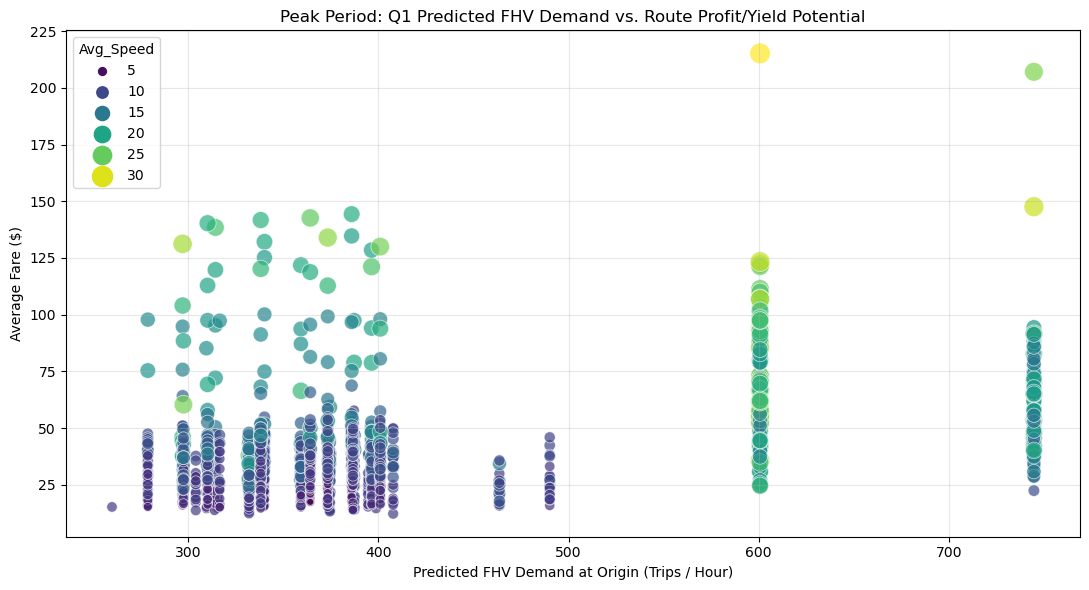

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def minmax(s):
    return (s - s.min()) / (s.max() - s.min() + 1e-9)

has_fare = df_all["Fare"].notna().sum() > 0
if has_fare:
    df_all["Rev_Per_Min"] = df_all["Fare"] / df_all["Duration_Min"]

# 彙總各 (Period, PULocationID, DOLocationID) 路線表現
route_stats = (
    df_all[df_all["PULocationID"].isin(q1_pred_summary["PULocationID"].unique())]
    .groupby(["Period", "PULocationID", "DOLocationID"], as_index=False)
    .agg(
        Total_Trips=("Service", "count"),
        Yellow_Trips=("Is_Yellow", "sum"),
        Avg_Distance=("Distance_Mi", "mean"),
        Avg_Duration=("Duration_Min", "mean"),
        Avg_Speed=("Speed_MPH", "mean"),
        Avg_Fare=("Fare", "mean") if has_fare else ("Distance_Mi", "mean"),
        Avg_Rev_Per_Min=("Rev_Per_Min", "mean") if has_fare else ("Speed_MPH", "mean")
    )
)

# 合併 Q1 預測需求量（代表該起點時段的網約車需求動能）
route_stats = route_stats.merge(
    q1_pred_summary,
    on=["Period", "PULocationID"],
    how="left"
)
route_stats["Pred_FHV_Demand"] = route_stats["Pred_FHV_Demand"].fillna(0)

# 過濾具一定樣本數的路線，避免極端少數行程干擾
viable_routes = route_stats[
    (route_stats["Total_Trips"] >= 200) &
    (route_stats["Yellow_Trips"] >= 30)
].copy()

if has_fare:
    viable_routes["Profit_Route_Score"] = (
        0.35 * minmax(viable_routes["Pred_FHV_Demand"]) +
        0.35 * minmax(viable_routes["Avg_Fare"]) +
        0.30 * minmax(viable_routes["Avg_Rev_Per_Min"])
    )
    y_col = "Avg_Fare"
    y_label = "Average Fare ($)"
else:
    viable_routes["Yield_Proxy"] = viable_routes["Avg_Distance"] * viable_routes["Avg_Speed"]
    viable_routes["Profit_Route_Score"] = (
        0.40 * minmax(viable_routes["Pred_FHV_Demand"]) +
        0.40 * minmax(viable_routes["Yield_Proxy"]) +
        0.20 * minmax(viable_routes["Avg_Speed"])
    )
    y_col = "Yield_Proxy"
    y_label = "Avg Distance × Avg Speed (Proxy)"

for period_name in ["Peak", "Off-Peak"]:
    print(f"\n=== [{period_name}] Top 8 有利潤潛力路線（PU -> DO）===")
    top_r = (
        viable_routes[viable_routes["Period"] == period_name]
        .sort_values("Profit_Route_Score", ascending=False)
        .head(8)
    )
    display(
        top_r[[
            "PULocationID", "DOLocationID", "Pred_FHV_Demand",
            "Total_Trips", "Yellow_Trips", "Avg_Distance",
            "Avg_Duration", "Avg_Speed", y_col, "Profit_Route_Score"
        ]].round(2)
    )

# 視覺化：尖峰時段「起點預測需求 vs. 路線收益潛力」
plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=viable_routes[viable_routes["Period"] == "Peak"],
    x="Pred_FHV_Demand",
    y=y_col,
    size="Avg_Speed",
    hue="Avg_Speed",
    palette="viridis",
    sizes=(25, 220),
    alpha=0.7
)
plt.title("Peak Period: Q1 Predicted FHV Demand vs. Route Profit/Yield Potential")
plt.xlabel("Predicted FHV Demand at Origin (Trips / Hour)")
plt.ylabel(y_label)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Yellow Taxi Strategy

Target high-demand FHV zones: Focus on Zone 138 and other high-ratio areas.

Capture high-fare routes: Target long-distance routes (e.g., 138 → 1, 132 → 1, 138 → 265).

Improve trip efficiency: Focus on short, fast-turnaround routes (e.g., 129 → 138 during off-peak hours).

Goal: Balance revenue potential and trip efficiency.

In [15]:
import numpy as np
import pandas as pd


def classify_period(weekday, hour):
    is_weekend = weekday in ["Saturday", "Sunday"]
    if not is_weekend:
        return "Peak" if ((7 <= hour <= 9) or (16 <= hour <= 19)) else "Off-Peak"
    else:
        return "Peak" if (12 <= hour <= 22) else "Off-Peak"


def pick_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None


# 1. 若 df_all 尚未建立，自動從 yellow_q1 與 uberlyft_q1 建立
if "df_all" not in globals():
    y_dur_col = pick_col(yellow_q1, ["Trip_Duration", "trip_minutes", "duration_min"])
    u_dur_col = pick_col(uberlyft_q1, ["Trip_Duration", "trip_minutes", "duration_min"])

    y_dist_col = pick_col(yellow_q1, ["trip_distance", "Distance_Mi", "trip_miles"])
    u_dist_col = pick_col(uberlyft_q1, ["trip_miles", "Distance_Mi", "trip_distance"])

    y_spd_col = pick_col(yellow_q1, ["Average_Speed", "Speed_MPH", "speed_mph"])
    u_spd_col = pick_col(uberlyft_q1, ["Average_Speed", "Speed_MPH", "speed_mph"])

    # 優先使用 base fare，其次才是 total_amount / fare_amount
    y_fare_col = pick_col(yellow_q1, ["fare_amount", "base_passenger_fare", "total_amount"])
    u_fare_col = pick_col(uberlyft_q1, ["base_passenger_fare", "fare_amount", "total_amount"])

    yellow_base = pd.DataFrame({
        "Service": "Yellow Taxi",
        "Date": yellow_q1["Date"],
        "Weekday": yellow_q1["Weekday"],
        "Hour": yellow_q1["Hour"],
        "PULocationID": yellow_q1["PULocationID"],
        "DOLocationID": yellow_q1["DOLocationID"],
        "Duration_Min": yellow_q1[y_dur_col] if y_dur_col else np.nan,
        "Distance_Mi": yellow_q1[y_dist_col] if y_dist_col else np.nan,
        "Speed_MPH": yellow_q1[y_spd_col] if y_spd_col else np.nan,
        "Fare": pd.to_numeric(yellow_q1[y_fare_col], errors="coerce") if y_fare_col else np.nan,
    })

    uberlyft_base = pd.DataFrame({
        "Service": uberlyft_q1["Service"] if "Service" in uberlyft_q1.columns else "FHV",
        "Date": uberlyft_q1["Date"],
        "Weekday": uberlyft_q1["Weekday"],
        "Hour": uberlyft_q1["Hour"],
        "PULocationID": uberlyft_q1["PULocationID"],
        "DOLocationID": uberlyft_q1["DOLocationID"],
        "Duration_Min": uberlyft_q1[u_dur_col] if u_dur_col else np.nan,
        "Distance_Mi": uberlyft_q1[u_dist_col] if u_dist_col else np.nan,
        "Speed_MPH": uberlyft_q1[u_spd_col] if u_spd_col else np.nan,
        "Fare": pd.to_numeric(uberlyft_q1[u_fare_col], errors="coerce") if u_fare_col else np.nan,
    })

    df_all = (
        pd.concat([yellow_base, uberlyft_base], ignore_index=True)
        .dropna(subset=["PULocationID", "DOLocationID"])
        .copy()
    )
    df_all["PULocationID"] = df_all["PULocationID"].astype(int)
    df_all["DOLocationID"] = df_all["DOLocationID"].astype(int)
    df_all["Period"] = [
        classify_period(w, h) for w, h in zip(df_all["Weekday"], df_all["Hour"])
    ]
    df_all["Is_Yellow"] = df_all["Service"] == "Yellow Taxi"

# 2. 確保 hours_per_period 與 q3_fill_rec 存在
if "hours_per_period" not in globals():
    hours_per_period = (
        df_all.groupby("Period")[["Date", "Hour"]]
        .drop_duplicates()
        .groupby("Period")
        .size()
        .to_dict()
    )

if "q3_fill_rec" not in globals():
    target_pu = q1_pred_summary["PULocationID"].unique()
    yellow_pu_actual = (
        df_all[(df_all["Is_Yellow"]) & (df_all["PULocationID"].isin(target_pu))]
        .groupby(["Period", "PULocationID"], as_index=False)
        .agg(
            Actual_Yellow_Trips=("Service", "count"),
            Avg_Yellow_Speed=("Speed_MPH", "mean"),
            Avg_Yellow_Distance=("Distance_Mi", "mean"),
        )
    )
    yellow_pu_actual["Avg_Hourly_Yellow"] = yellow_pu_actual.apply(
        lambda r: r["Actual_Yellow_Trips"] / max(hours_per_period.get(r["Period"], 1), 1),
        axis=1,
    )
    q3_fill_rec = q1_pred_summary.merge(
        yellow_pu_actual, on=["Period", "PULocationID"], how="left"
    )
    q3_fill_rec["Actual_Yellow_Trips"] = q3_fill_rec["Actual_Yellow_Trips"].fillna(0)
    q3_fill_rec["Avg_Hourly_Yellow"] = q3_fill_rec["Avg_Hourly_Yellow"].fillna(0)
    q3_fill_rec["Pred_Demand_to_Yellow_Ratio"] = (
        q3_fill_rec["Pred_FHV_Demand"] / (q3_fill_rec["Avg_Hourly_Yellow"] + 0.1)
    )

    def minmax(s):
        return (s - s.min()) / (s.max() - s.min() + 1e-9)

    q3_fill_rec["Priority_Score"] = (
        0.55 * minmax(q3_fill_rec["Pred_FHV_Demand"])
        + 0.45 * minmax(q3_fill_rec["Pred_Demand_to_Yellow_Ratio"])
    )

# 3. 計算各 (Period, PULocationID) 的平均單趟車資（Yellow 與 FHV）
fare_by_pu = (
    df_all[df_all["PULocationID"].isin(q3_fill_rec["PULocationID"].unique())]
    .groupby(["Period", "PULocationID", "Is_Yellow"], as_index=False)["Fare"]
    .mean()
    .pivot(index=["Period", "PULocationID"], columns="Is_Yellow", values="Fare")
    .reset_index()
    .rename(columns={True: "Avg_Yellow_Fare", False: "Avg_FHV_Fare"})
)

q3_profit = q3_fill_rec.merge(fare_by_pu, on=["Period", "PULocationID"], how="left")

# 優先用該區實際 Yellow 平均車資，不足時用 FHV 平均車資替代
q3_profit["Est_Trip_Fare"] = np.where(
    (q3_profit["Actual_Yellow_Trips"] >= 10) & (q3_profit["Avg_Yellow_Fare"].notna()),
    q3_profit["Avg_Yellow_Fare"],
    q3_profit["Avg_FHV_Fare"],
)

# 4. 情境參數與增量營收／利潤計算
capture_rates = {
    "Conservative_5pct": 0.05,
    "Base_10pct": 0.10,
    "Optimistic_15pct": 0.15,
}
profit_margin = 0.70

for label, rate in capture_rates.items():
    q3_profit[f"Add_Trips_Hr_{label}"] = q3_profit["Pred_FHV_Demand"] * rate
    q3_profit[f"Add_Rev_Hr_{label}"] = (
        q3_profit[f"Add_Trips_Hr_{label}"] * q3_profit["Est_Trip_Fare"]
    )
    q3_profit[f"Add_Profit_Hr_{label}"] = (
        q3_profit[f"Add_Rev_Hr_{label}"] * profit_margin
    )

q3_profit["Total_Period_Hours"] = q3_profit["Period"].map(hours_per_period)
q3_profit["Total_Monthly_Profit_Base10pct"] = (
    q3_profit["Add_Profit_Hr_Base_10pct"] * q3_profit["Total_Period_Hours"]
)

for period_name in ["Peak", "Off-Peak"]:
    print(
        f"\n=== [{period_name}] Top 8 優先填補熱區：預估增量營收與利潤（基準情境 10% 搶單率）==="
    )
    top8 = (
        q3_profit[q3_profit["Period"] == period_name]
        .sort_values("Priority_Score", ascending=False)
        .head(8)
    )
    display(
        top8[[
            "PULocationID",
            "Pred_FHV_Demand",
            "Avg_FHV_Fare",
            "Est_Trip_Fare",
            "Add_Trips_Hr_Base_10pct",
            "Add_Rev_Hr_Base_10pct",
            "Add_Profit_Hr_Base_10pct",
            "Total_Monthly_Profit_Base10pct",
        ]].round(2)
    )

top8_all = (
    q3_profit.sort_values(["Period", "Priority_Score"], ascending=[True, False])
    .groupby("Period")
    .head(8)
)

summary_scenarios = []
for label, rate in capture_rates.items():
    total_hr_rev = top8_all[f"Add_Rev_Hr_{label}"].sum()
    total_hr_profit = top8_all[f"Add_Profit_Hr_{label}"].sum()
    total_month_profit = (
        top8_all[f"Add_Profit_Hr_{label}"] * top8_all["Total_Period_Hours"]
    ).sum()
    summary_scenarios.append({
        "Scenario": label,
        "Capture_Rate": f"{rate*100:.0f}%",
        "Combined_Hourly_Rev ($)": round(total_hr_rev, 2),
        "Combined_Hourly_Profit ($)": round(total_hr_profit, 2),
        "Est_Total_Period_Profit ($)": round(total_month_profit, 2),
    })

print("\n=== Top 8 熱區合計：不同搶單率情境下的總增量利潤預估 ===")
display(pd.DataFrame(summary_scenarios))

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.

=== [Peak] Top 8 優先填補熱區：預估增量營收與利潤（基準情境 10% 搶單率）===


,PULocationID,Pred_FHV_Demand,Avg_FHV_Fare,Est_Trip_Fare,Add_Trips_Hr_Base_10pct,Add_Rev_Hr_Base_10pct,Add_Profit_Hr_Base_10pct,Total_Monthly_Profit_Base10pct
44,138,744.78,NaN,72.61,74.48,5407.57,3785.30,972822.10
37,76,463.61,NaN,33.14,46.36,1536.37,1075.46,276392.66
50,181,398.75,NaN,35.57,39.87,1418.39,992.88,255169.05
42,130,313.73,NaN,41.61,31.37,1305.29,913.70,234821.77
35,61,490.08,NaN,34.53,49.01,1692.21,1184.55,304429.27
32,37,394.54,NaN,35.64,39.45,1406.11,984.28,252959.88
40,112,407.72,NaN,36.06,40.77,1470.26,1029.18,264500.34
41,129,309.47,NaN,41.62,30.95,1287.97,901.58,231704.95



=== [Off-Peak] Top 8 優先填補熱區：預估增量營收與利潤（基準情境 10% 搶單率）===


,PULocationID,Pred_FHV_Demand,Avg_FHV_Fare,Est_Trip_Fare,Add_Trips_Hr_Base_10pct,Add_Rev_Hr_Base_10pct,Add_Profit_Hr_Base_10pct,Total_Monthly_Profit_Base10pct
14,138,537.15,NaN,71.42,53.72,3836.50,2685.55,1307862.90
5,61,325.63,NaN,33.55,32.56,1092.37,764.66,372389.13
7,76,277.50,NaN,33.52,27.75,930.31,651.22,317143.94
2,37,318.66,NaN,35.31,31.87,1125.25,787.68,383599.33
12,130,211.43,NaN,38.25,21.14,808.81,566.17,275724.28
11,129,215.56,NaN,38.01,21.56,819.31,573.52,279301.88
1,36,242.41,NaN,34.80,24.24,843.61,590.53,287588.14
20,181,224.78,NaN,35.57,22.48,799.63,559.74,272595.12



=== Top 8 熱區合計：不同搶單率情境下的總增量利潤預估 ===


,Scenario,Capture_Rate,Combined_Hourly_Rev ($),Combined_Hourly_Profit ($),Est_Total_Period_Profit ($)
0,Conservative_5pct,5%,12889.99,9023.00,3144502.38
1,Base_10pct,10%,25779.99,18045.99,6289004.76
2,Optimistic_15pct,15%,38669.98,27068.99,9433507.14


### Methodology & Key Findings
- Methodology: Combines forecasted FHV demand, estimated Yellow Taxi fares, and a 70% profit margin under three scenarios: Conservative (5%), Base (10%), and Optimistic (15%).

- Top Zone – Zone 138: Leads both Peak and Off-Peak periods, with average fares of $71–73 per trip. Estimated monthly profit reaches 973K (Peak) and 1.31M (Off-Peak) under the 10% base scenario.

- Other Top 8 Zones: Generate additional profit, with average fares of $33–42 per trip.

- Combined Profit: Estimated monthly profit across the Top 8 zones ranges from 3.14M (5%) to 6.29M (10%) and $9.43M (15%).

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams["axes.unicode_minus"] = False

# 1. 正確計算各時段總小時數（避免 DataFrameGroupBy.drop_duplicates 報錯）
hours_per_period = (
    df_all[["Period", "Date", "Hour"]]
    .drop_duplicates()
    .groupby("Period")
    .size()
    .to_dict()
)

# 2. 若 q3_profit 尚未建立，則計算基準單趟車資與三種情境利潤
if "q3_profit" not in globals():
    fare_by_pu = (
        df_all[df_all["PULocationID"].isin(q3_fill_rec["PULocationID"].unique())]
        .groupby(["Period", "PULocationID", "Is_Yellow"], as_index=False)["Fare"]
        .mean()
        .pivot(index=["Period", "PULocationID"], columns="Is_Yellow", values="Fare")
        .reset_index()
        .rename(columns={True: "Avg_Yellow_Fare", False: "Avg_FHV_Fare"})
    )
    q3_profit = q3_fill_rec.merge(fare_by_pu, on=["Period", "PULocationID"], how="left")
    q3_profit["Est_Trip_Fare"] = np.where(
        (q3_profit["Actual_Yellow_Trips"] >= 10) & (q3_profit["Avg_Yellow_Fare"].notna()),
        q3_profit["Avg_Yellow_Fare"],
        q3_profit["Avg_FHV_Fare"],
    )

    capture_rates = {
        "Conservative_5pct": 0.05,
        "Base_10pct": 0.10,
        "Optimistic_15pct": 0.15,
    }
    profit_margin = 0.70

    for label, rate in capture_rates.items():
        q3_profit[f"Add_Trips_Hr_{label}"] = q3_profit["Pred_FHV_Demand"] * rate
        q3_profit[f"Add_Rev_Hr_{label}"] = (
            q3_profit[f"Add_Trips_Hr_{label}"] * q3_profit["Est_Trip_Fare"]
        )
        q3_profit[f"Add_Profit_Hr_{label}"] = (
            q3_profit[f"Add_Rev_Hr_{label}"] * profit_margin
        )

q3_profit["Total_Period_Hours"] = q3_profit["Period"].map(hours_per_period)

# 取出 Peak 與 Off-Peak 各自的 Top 8 優先填補熱區供後續繪圖使用
top8_plot = (
    q3_profit.sort_values(["Period", "Priority_Score"], ascending=[True, False])
    .groupby("Period")
    .head(8)
    .copy()
)

colors = {"Peak": "#E67E22", "Off-Peak": "#2E86C1"}
print("Data preparation complete. Top 8 zones per period ready for plotting.")

Data preparation complete. Top 8 zones per period ready for plotting.


## PART 5: Estimate Additional Revenue and Profit for Yellow Taxis

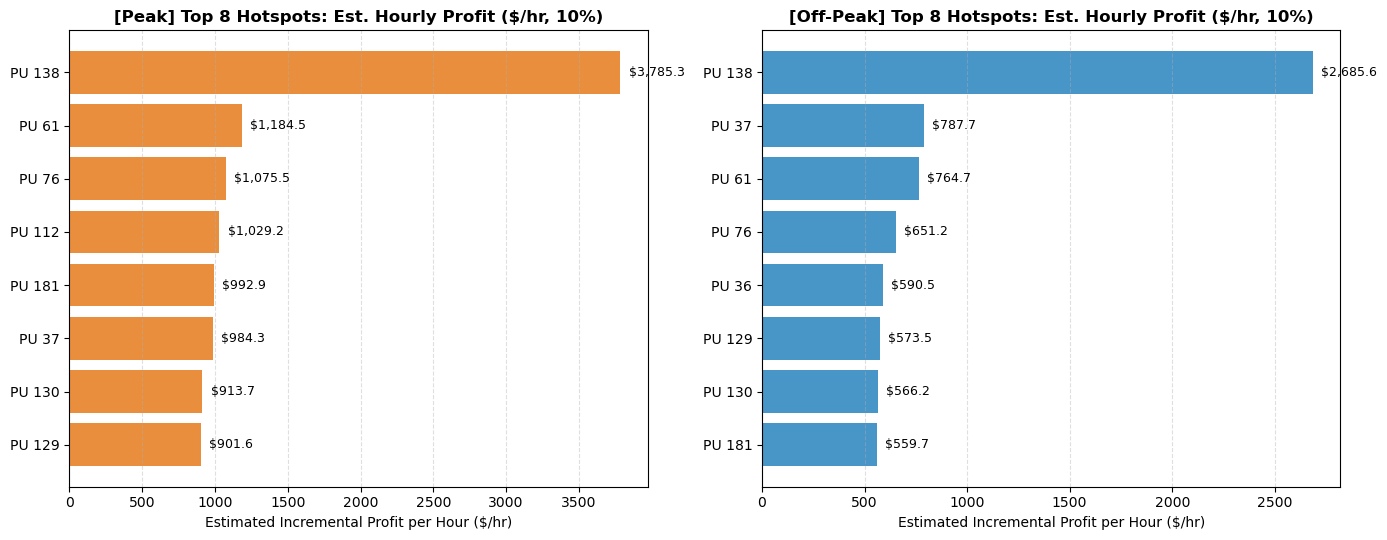

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=False)

for ax, period_name in zip(axes, ["Peak", "Off-Peak"]):
    sub = (
        top8_plot[top8_plot["Period"] == period_name]
        .sort_values("Add_Profit_Hr_Base_10pct", ascending=True)
    )
    labels = [f"PU {int(pid)}" for pid in sub["PULocationID"]]
    vals = sub["Add_Profit_Hr_Base_10pct"]

    bars = ax.barh(labels, vals, color=colors[period_name], alpha=0.88)
    ax.set_title(
        f"[{period_name}] Top 8 Hotspots: Est. Hourly Profit ($/hr, 10%)",
        fontsize=12,
        fontweight="bold",
    )
    ax.set_xlabel("Estimated Incremental Profit per Hour ($/hr)")
    ax.grid(axis="x", linestyle="--", alpha=0.4)

    for bar, v in zip(bars, vals):
        ax.text(
            v + max(vals) * 0.015,
            bar.get_y() + bar.get_height() / 2,
            f"${v:,.1f}",
            va="center",
            ha="left",
            fontsize=9,
        )

plt.tight_layout()
plt.show()

### Estimated Additional Monthly Profit

1. Top 8 Zones: USD 3.14M (5%), USD 6.29M (10%), and USD 9.43M (15%).

2. Top Performer – Zone 138: Highest profit potential, with estimated monthly profit of USD 973K (Peak) and USD 1.31M (Off-Peak) under the 10% scenario.

3. Other Top Zones: Provide additional profit and help diversify revenue.

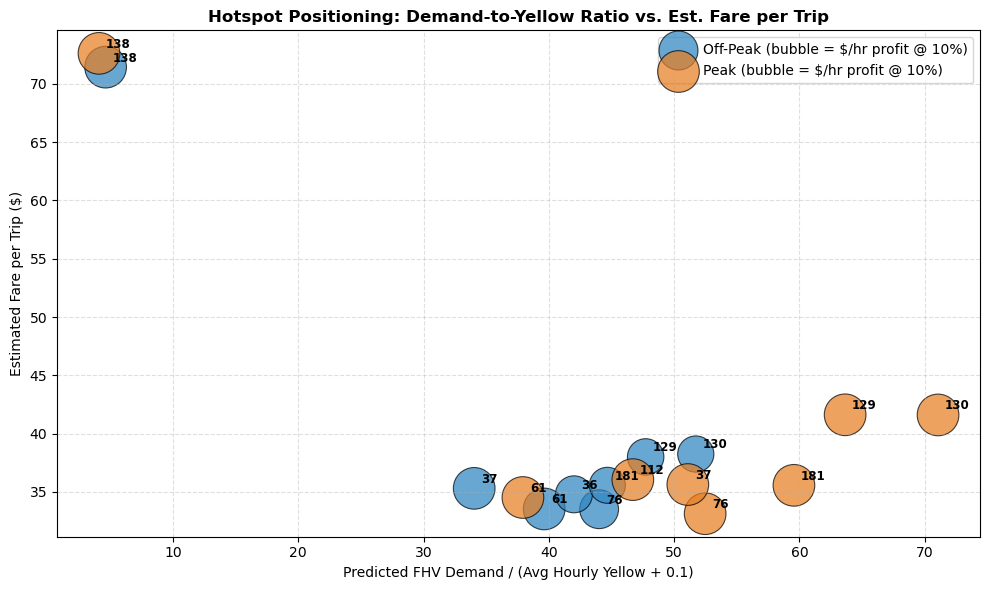

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))

for period_name, grp in top8_plot.groupby("Period"):
    ax.scatter(
        grp["Pred_Demand_to_Yellow_Ratio"],
        grp["Est_Trip_Fare"],
        s=np.clip(grp["Add_Profit_Hr_Base_10pct"] * 1.2, 60, 900),
        c=colors.get(period_name, "#555555"),
        alpha=0.72,
        edgecolors="black",
        linewidths=0.8,
        label=f"{period_name} (bubble = $/hr profit @ 10%)",
    )
    for _, r in grp.iterrows():
        ax.annotate(
            f"{int(r['PULocationID'])}",
            (r["Pred_Demand_to_Yellow_Ratio"], r["Est_Trip_Fare"]),
            textcoords="offset points",
            xytext=(5, 4),
            fontsize=8.5,
            fontweight="bold",
        )

ax.set_title(
    "Hotspot Positioning: Demand-to-Yellow Ratio vs. Est. Fare per Trip",
    fontsize=12,
    fontweight="bold",
)
ax.set_xlabel("Predicted FHV Demand / (Avg Hourly Yellow + 0.1)")
ax.set_ylabel("Estimated Fare per Trip ($)")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="best")
plt.tight_layout()
plt.show()

#### Figure 2 — Supply-Demand Gap Ratio vs. Average Fare per Trip (Bubble Chart)

This bubble chart positions the Top 8 hotspots across two strategic dimensions: the horizontal axis shows the Demand-to-Yellow Supply Ratio, the vertical axis shows the Estimated Fare per Trip ($), and bubble size represents Hourly Incremental Profit. Zones in the upper-right quadrant indicate severe Yellow Taxi undersupply paired with high fares (high-margin opportunities), whereas lower-right zones represent high-turnover, lower-fare corridors—supporting differentiated dispatch strategies.

### PART 5: Projected Profit Sensitivity Analysis (5% / 10% / 15% Absorption Scenarios, USD)
These two charts show how much extra profit Yellow Taxis could make across the Top 8 priority zones under three demand-capture scenarios: Conservative (5%), Base (10%), and Optimistic (15%).

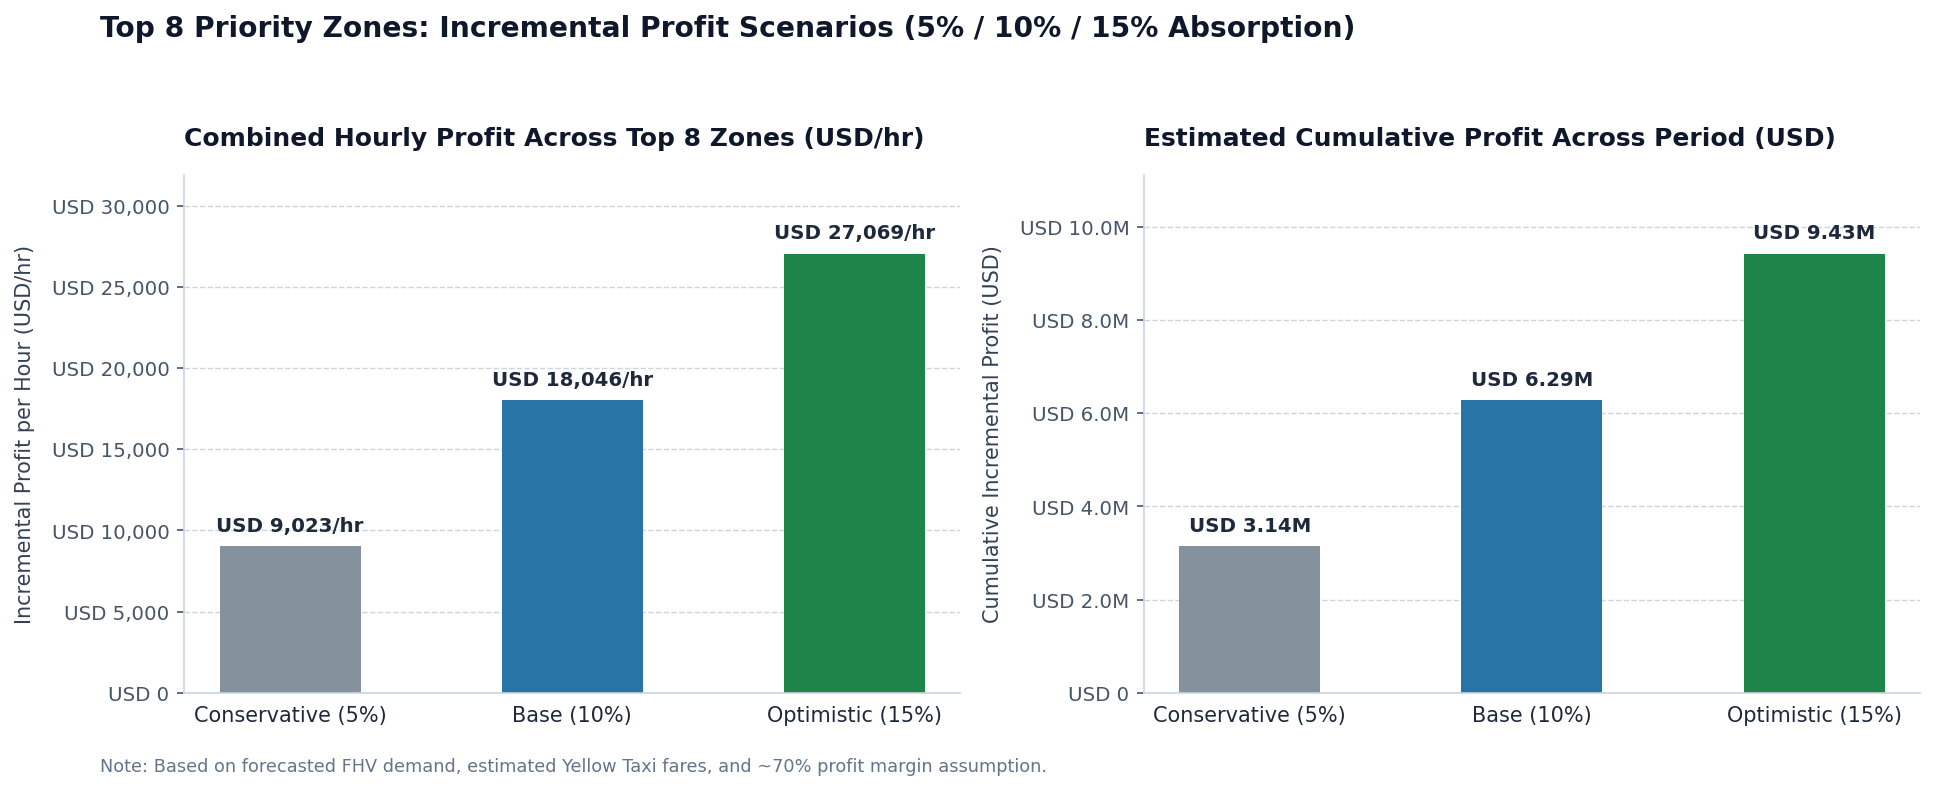

In [16]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

scenario_labels = ["Conservative (5%)", "Base (10%)", "Optimistic (15%)"]
scenario_keys = ["Conservative_5pct", "Base_10pct", "Optimistic_15pct"]

hr_profits = [top8_plot[f"Add_Profit_Hr_{k}"].sum() for k in scenario_keys]
period_profits = [
    (top8_plot[f"Add_Profit_Hr_{k}"] * top8_plot["Total_Period_Hours"]).sum()
    for k in scenario_keys
]

# 全域字體與樣式微調（可依環境替換為 Arial / Helvetica / Noto Sans CJK TC）
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]
plt.rcParams["axes.edgecolor"] = "#CBD5E1"
plt.rcParams["axes.linewidth"] = 0.8

colors = ["#85929E", "#2874A6", "#1E8449"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), dpi=150)
fig.patch.set_facecolor("white")


def style_axis(ax, title, ylabel, y_formatter, max_val):
    ax.set_facecolor("white")
    ax.set_title(
        title, fontsize=12, fontweight="bold", color="#0F172A", pad=14, loc="left"
    )
    ax.set_ylabel(ylabel, fontsize=10, color="#334155", labelpad=8)
    ax.tick_params(axis="x", labelsize=10, colors="#1E293B", length=0, pad=6)
    ax.tick_params(axis="y", labelsize=9.5, colors="#475569")
    ax.yaxis.set_major_formatter(FuncFormatter(y_formatter))
    ax.set_ylim(0, max_val * 1.18)  # 留出上方空間放數值標籤
    ax.yaxis.grid(True, linestyle="--", linewidth=0.7, alpha=0.45, color="#94A3B8")
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


# 左圖：每小時合計增量利潤（千分位 USD）
bars1 = ax1.bar(scenario_labels, hr_profits, color=colors, width=0.5, edgecolor="none")
style_axis(
    ax1,
    title="Combined Hourly Profit Across Top 8 Zones (USD/hr)",
    ylabel="Incremental Profit per Hour (USD/hr)",
    y_formatter=lambda x, _: f"USD {x:,.0f}",
    max_val=max(hr_profits),
)
for b, v in zip(bars1, hr_profits):
    ax1.text(
        b.get_x() + b.get_width() / 2,
        v + max(hr_profits) * 0.025,
        f"USD {v:,.0f}/hr",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
        color="#1E293B",
    )

# 右圖：期間累計增量利潤（百萬 USD 簡潔標示）
bars2 = ax2.bar(
    scenario_labels, period_profits, color=colors, width=0.5, edgecolor="none"
)
style_axis(
    ax2,
    title="Estimated Cumulative Profit Across Period (USD)",
    ylabel="Cumulative Incremental Profit (USD)",
    y_formatter=lambda x, _: f"USD {x / 1e6:.1f}M" if x >= 1e6 else f"USD {x:,.0f}",
    max_val=max(period_profits),
)
for b, v in zip(bars2, period_profits):
    ax2.text(
        b.get_x() + b.get_width() / 2,
        v + max(period_profits) * 0.025,
        f"USD {v / 1e6:.2f}M",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
        color="#1E293B",
    )

fig.suptitle(
    "Top 8 Priority Zones: Incremental Profit Scenarios (5% / 10% / 15% Absorption)",
    fontsize=13.5,
    fontweight="bold",
    color="#0F172A",
    x=0.055,
    y=0.98,
    ha="left",
)
fig.text(
    0.055,
    0.01,
    "Note: Based on forecasted FHV demand, estimated Yellow Taxi fares, and ~70% profit margin assumption.",
    fontsize=8.5,
    color="#64748B",
)

plt.tight_layout(rect=[0, 0.04, 1, 0.93])
plt.show()

# Recommendation:

### 1. Identifying High-Potential Areas for FHV Growth
To identify where Yellow Taxis can best complement high-demand FHV zones, we rank candidate pickup areas using the priority score formula:$$\text{Priority\_Score} = 0.55 \times \widetilde{\text{Pred\_FHV\_Demand}} + 0.45 \times \widetilde{\text{Pred\_Demand\_to\_Yellow\_Ratio}}$$

### 2. Hub Leadership, Gap Zones, and Off-Peak Efficiency:
Zone 138 leads in both Peak and Off-Peak periods on the strength of high demand volume and steady speeds, while high-ratio zones offer additional coverage opportunities. Higher average speeds during Off-Peak hours support faster trip turnover, whereas traffic congestion in select Peak zones warrants more selective positioning.

### 3. Balancing High-Fare Routes with Fast Turnaround:
Long-distance corridors (such as 138 -> 1, 132 -> 1, and 138 -> 265) deliver high per-trip fares, while fast, high-value routes like 129 -> 138 during Off-Peak hours highlight strong time efficiency—indicating value in tailoring route choices to time of day.

### 4. Meaningful Profit Upside Subject to Operational Assumptions:

Across Conservative (5%), Base (10%), and Optimistic (15%) demand-absorption scenarios, combined estimated period profit across the Top 8 zones reaches USD 3.14M, USD 6.29M, and USD 9.43M, respectively, led by Zone 138. Because these figures rely on estimated trip fares and a ~70% profit margin assumption, real-world outcomes will depend on deadhead mileage, wait times, and operating costs.
